# Project 1: model comparison

Evaluation protocol: random 5-fold CV (seed 42). `fit` runs on the training part of each fold only. One F1 threshold per model, chosen on the pooled out-of-fold scores. AUC and F1 are reported as mean ± std over folds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import create_csv_submission
from implementations import reg_logistic_regression, ROC_AUC
from learned_preprocess import fit, transform

## 1. Load

In [2]:
CLEAN_DIR = "data/clean/"

x_train  = np.load(CLEAN_DIR + "x_train_clean.npy")
x_test   = np.load(CLEAN_DIR + "x_test_clean.npy")
y_train  = np.load(CLEAN_DIR + "y_train.npy")       # -1 / +1
test_ids = np.load(CLEAN_DIR + "test_ids.npy")
with open(CLEAN_DIR + "columns.txt") as f:
    names = f.read().splitlines()

y = (y_train == 1).astype(float)                    # 0 / 1
print("x_train:", x_train.shape, " positives:", f"{y.mean():.1%}")

x_train: (328135, 42)  positives: 8.8%


## 2. Helpers

In [3]:
def sigmoid(z):
    return 0.5 * (1 + np.tanh(0.5 * z))

def f1_score(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    if tp == 0:
        return 0.0
    p, r = tp / (tp + fp), tp / (tp + fn)
    return 2 * p * r / (p + r)

def best_threshold(y_true, scores, grid=np.arange(0.05, 0.95, 0.01)):
    f1s = [f1_score(y_true, (scores >= t).astype(float)) for t in grid]
    return grid[int(np.argmax(f1s))], max(f1s)

## 3. Folds

`fit` uses the training part of each fold only. All models reuse these matrices.

In [4]:
K, SEED = 5, 42
rng = np.random.default_rng(SEED)
parts = np.array_split(rng.permutation(len(y)), K)

folds = []
for i in range(K):
    va = parts[i]
    tr = np.concatenate([parts[j] for j in range(K) if j != i])
    params = fit(x_train[tr], names)
    X_tr, feat_names = transform(x_train[tr], params)
    X_va, _          = transform(x_train[va], params)
    folds.append((X_tr, y[tr], X_va, y[va]))
print("Folds ready. Features per fold:", folds[0][0].shape[1])

Folds ready. Features per fold: 87


## 4. Evaluation and plotting functions

In [5]:
results = {}       # name -> (auc_mean, auc_std, f1_mean, f1_std, thr)
fold_scores = {}   # name -> (per-fold AUC, per-fold F1), used for paired comparisons
oof = {}           # name -> (pooled scores, pooled labels)

def evaluate(name, model, show=True, force=False):
    """Run model on every fold. The F1 threshold is chosen once on the pooled
    out-of-fold scores, then applied to each fold."""
    if name in results and not force:
        print(f"skip {name} (already done, use force=True to rerun)")
        return
    aucs, sc, lab = [], [], []
    for X_tr, y_tr, X_va, y_va in folds:
        score = model(X_tr, y_tr, X_va)
        _, _, auc = ROC_AUC(y_va, score)
        aucs.append(auc)
        sc.append(score)
        lab.append(y_va)
    thr, _ = best_threshold(np.concatenate(lab), np.concatenate(sc))
    f1s = [f1_score(l, (s >= thr).astype(float)) for s, l in zip(sc, lab)]
    results[name] = (np.mean(aucs), np.std(aucs), np.mean(f1s), np.std(f1s), thr)
    fold_scores[name] = (np.array(aucs), np.array(f1s))
    oof[name] = (np.concatenate(sc), np.concatenate(lab))
    if show:
        show_results()

def show_results():
    print(f"{'model':<38}{'AUC':>17}{'F1':>17}{'thr':>6}")
    for n, (a, sa, f, sf, t) in sorted(results.items(), key=lambda kv: -kv[1][0]):
        print(f"{n:<38}{a:>10.4f}±{sa:.4f}{f:>10.4f}±{sf:.4f}{t:>6.2f}")

def compare(a, b):
    """Paired fold-by-fold difference, b minus a. Folds are identical across models."""
    da = fold_scores[b][0] - fold_scores[a][0]
    df = fold_scores[b][1] - fold_scores[a][1]
    print(f"{b}  vs  {a}")
    print(f"  dAUC {da.mean():+.4f} ± {da.std():.4f}  (better in {(da > 0).sum()}/{len(da)} folds)")
    print(f"  dF1  {df.mean():+.4f} ± {df.std():.4f}  (better in {(df > 0).sum()}/{len(df)} folds)")

def plot_performance(names, grid=np.arange(0.05, 0.95, 0.01)):
    """ROC curve and F1 against threshold for models already run with evaluate()."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for name in names:
        sc, lab = oof[name]
        fpr, tpr, auc = ROC_AUC(lab, sc)
        f1s = [f1_score(lab, (sc >= t).astype(float)) for t in grid]
        t_best = grid[int(np.argmax(f1s))]
        ax[0].plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")
        ax[1].plot(grid, f1s, label=f"{name} (thr {t_best:.2f}, F1 {max(f1s):.3f})")
    ax[0].plot([0, 1], [0, 1], "--", color="gray")
    ax[0].set_xlabel("false positive rate")
    ax[0].set_ylabel("true positive rate")
    ax[0].set_title("ROC (out-of-fold)")
    ax[0].legend(fontsize=7)
    ax[1].set_xlabel("threshold")
    ax[1].set_ylabel("F1")
    ax[1].set_title("F1 against threshold")
    ax[1].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

def plot_sweep(values, name_fn, xlabel, log_x=True):
    """CV AUC and F1 (mean ± std over folds) against one hyperparameter."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for a, (im, isd), lab in zip(ax, ((0, 1), (2, 3)), ("CV AUC", "CV F1")):
        m  = [results[name_fn(v)][im] for v in values]
        sd = [results[name_fn(v)][isd] for v in values]
        a.errorbar(values, m, yerr=sd, fmt="o-", capsize=3)
        if log_x:
            a.set_xscale("log")
        a.set_xlabel(xlabel)
        a.set_ylabel(lab)
    plt.tight_layout()
    plt.show()

## Model 1: regularized logistic regression (baseline)

In [6]:
MAX_ITERS, GAMMA = 1000, 0.1

def model_rl(X_tr, y_tr, X_va, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    w, _ = reg_logistic_regression(y_tr, X_tr, lam, np.zeros(X_tr.shape[1]), iters, gamma)
    return sigmoid(X_va @ w)

evaluate("logreg lam=1e-4 it=1000", model_rl)

model                                               AUC               F1   thr
logreg lam=1e-4 it=1000                   0.8536±0.0021    0.4150±0.0019  0.18


### Model 1: hyperparameters

The lambda sweep runs at 300 iterations to save time. The iteration sweep uses lambda 1e-4.

In [7]:
"""SWEEP_ITERS = 300
lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
for lam in lambdas:
    evaluate(f"logreg lam={lam:g} it={SWEEP_ITERS}",
             lambda X, y, V, lam=lam: model_rl(X, y, V, lam=lam, iters=SWEEP_ITERS), show=False)

iters_list = [100, 300, 1000]
for it in iters_list:
    evaluate(f"logreg lam=1e-4 it={it}",
             lambda X, y, V, it=it: model_rl(X, y, V, iters=it), show=False)

show_results()"""

'SWEEP_ITERS = 300\nlambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]\nfor lam in lambdas:\n    evaluate(f"logreg lam={lam:g} it={SWEEP_ITERS}",\n             lambda X, y, V, lam=lam: model_rl(X, y, V, lam=lam, iters=SWEEP_ITERS), show=False)\n\niters_list = [100, 300, 1000]\nfor it in iters_list:\n    evaluate(f"logreg lam=1e-4 it={it}",\n             lambda X, y, V, it=it: model_rl(X, y, V, iters=it), show=False)\n\nshow_results()'

In [8]:
"""plot_sweep(lambdas, lambda v: f"logreg lam={v:g} it={SWEEP_ITERS}", "lambda")
plot_sweep(iters_list, lambda v: f"logreg lam=1e-4 it={v}", "iterations", log_x=False)"""

'plot_sweep(lambdas, lambda v: f"logreg lam={v:g} it={SWEEP_ITERS}", "lambda")\nplot_sweep(iters_list, lambda v: f"logreg lam=1e-4 it={v}", "iterations", log_x=False)'

### Model 1: convergence check

AUC was still rising between 300 and 1000 iterations. This run tells whether 1000 is enough.

In [9]:
evaluate("logreg lam=1e-4 it=3000", lambda X, y, V: model_rl(X, y, V, iters=3000))
compare("logreg lam=1e-4 it=1000", "logreg lam=1e-4 it=3000")

model                                               AUC               F1   thr
logreg lam=1e-4 it=3000                   0.8537±0.0021    0.4156±0.0011  0.18
logreg lam=1e-4 it=1000                   0.8536±0.0021    0.4150±0.0019  0.18
logreg lam=1e-4 it=3000  vs  logreg lam=1e-4 it=1000
  dAUC +0.0001 ± 0.0001  (better in 5/5 folds)
  dF1  +0.0006 ± 0.0018  (better in 4/5 folds)


## Model 2: logistic regression + squared continuous features

In [10]:
def add_squares(X_tr, X_va):
    """Append standardized squares of continuous columns (more than 10 distinct values).
    Statistics come from the training part only."""
    cont = [j for j in range(1, X_tr.shape[1]) if len(np.unique(X_tr[:, j])) > 10]
    sq_tr, sq_va = X_tr[:, cont] ** 2, X_va[:, cont] ** 2
    mu, sd = sq_tr.mean(axis=0), sq_tr.std(axis=0) + 1e-8
    return np.c_[X_tr, (sq_tr - mu) / sd], np.c_[X_va, (sq_va - mu) / sd]

def model_squares(X_tr, y_tr, X_va, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    A_tr, A_va = add_squares(X_tr, X_va)
    w, _ = reg_logistic_regression(y_tr, A_tr, lam, np.zeros(A_tr.shape[1]), iters, gamma)
    return sigmoid(A_va @ w)

evaluate("logreg + squares it=1000", model_squares)
compare("logreg lam=1e-4 it=1000", "logreg + squares it=1000")

model                                               AUC               F1   thr
logreg + squares it=1000                  0.8540±0.0021    0.4151±0.0021  0.18
logreg lam=1e-4 it=3000                   0.8537±0.0021    0.4156±0.0011  0.18
logreg lam=1e-4 it=1000                   0.8536±0.0021    0.4150±0.0019  0.18
logreg + squares it=1000  vs  logreg lam=1e-4 it=1000
  dAUC +0.0004 ± 0.0001  (better in 5/5 folds)
  dF1  +0.0001 ± 0.0011  (better in 3/5 folds)


## Model 3: class-weighted logistic regression 

Each sample gets a weight that depends on its class. `balance=0` is the plain loss, `balance=1` gives both classes the same total weight. Weights are rescaled to mean 1, so the step size stays comparable to the baseline. The bias (column 0) is not penalized.

In [11]:
def weighted_logistic_gd(X, y, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA, balance=1.0):
    """Class-weighted L2 logistic regression, full-batch gradient descent."""
    n, d = X.shape
    n_pos = y.sum()
    w_pos = (n / (2 * n_pos)) ** balance
    w_neg = (n / (2 * (n - n_pos))) ** balance
    sw = np.where(y == 1, w_pos, w_neg)
    sw = sw / sw.mean()
    w = np.zeros(d)
    pen = np.ones(d)
    pen[0] = 0.0                                   # no penalty on the bias
    for _ in range(iters):
        p = sigmoid(X @ w)
        grad = X.T @ (sw * (p - y)) / n + 2 * lam * pen * w
        w -= gamma * grad
    return w

def model_weighted(X_tr, y_tr, X_va, balance=1.0, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    return sigmoid(X_va @ weighted_logistic_gd(X_tr, y_tr, lam, iters, gamma, balance))

for b in [0.5, 1.0]:
    evaluate(f"weighted b={b} it=1000", lambda X, y, V, b=b: model_weighted(X, y, V, balance=b), show=False)
show_results()

model                                               AUC               F1   thr
logreg + squares it=1000                  0.8540±0.0021    0.4151±0.0021  0.18
weighted b=1.0 it=1000                    0.8539±0.0021    0.4163±0.0019  0.71
weighted b=0.5 it=1000                    0.8538±0.0021    0.4159±0.0019  0.42
logreg lam=1e-4 it=3000                   0.8537±0.0021    0.4156±0.0011  0.18
logreg lam=1e-4 it=1000                   0.8536±0.0021    0.4150±0.0019  0.18


weighted b=0.5 it=1000  vs  logreg lam=1e-4 it=1000
  dAUC +0.0002 ± 0.0001  (better in 5/5 folds)
  dF1  +0.0009 ± 0.0017  (better in 4/5 folds)
weighted b=1.0 it=1000  vs  logreg lam=1e-4 it=1000
  dAUC +0.0003 ± 0.0001  (better in 5/5 folds)
  dF1  +0.0013 ± 0.0009  (better in 4/5 folds)


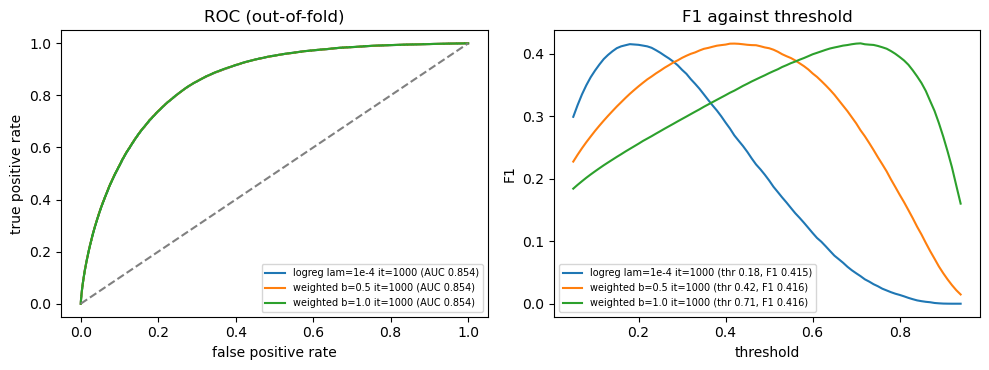

In [12]:
compare("logreg lam=1e-4 it=1000", "weighted b=0.5 it=1000")
compare("logreg lam=1e-4 it=1000", "weighted b=1.0 it=1000")
plot_performance(["logreg lam=1e-4 it=1000", "weighted b=0.5 it=1000", "weighted b=1.0 it=1000"])

### Optional: weighting + squares

Run this only if weighting or squares showed a gain above.

In [13]:
def model_weighted_squares(X_tr, y_tr, X_va, balance=1.0, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    A_tr, A_va = add_squares(X_tr, X_va)
    return sigmoid(A_va @ weighted_logistic_gd(A_tr, y_tr, lam, iters, gamma, balance))

evaluate("weighted b=0.5 + squares it=1000", lambda X, y, V: model_weighted_squares(X, y, V, balance=0.5))

model                                               AUC               F1   thr
weighted b=0.5 + squares it=1000          0.8542±0.0021    0.4163±0.0015  0.43
logreg + squares it=1000                  0.8540±0.0021    0.4151±0.0021  0.18
weighted b=1.0 it=1000                    0.8539±0.0021    0.4163±0.0019  0.71
weighted b=0.5 it=1000                    0.8538±0.0021    0.4159±0.0019  0.42
logreg lam=1e-4 it=3000                   0.8537±0.0021    0.4156±0.0011  0.18
logreg lam=1e-4 it=1000                   0.8536±0.0021    0.4150±0.0019  0.18
